# Version KAGGLE du projet rétine (artères / veines)
**Avant de lancer** (panneau de droite, « Session options ») : Accelerator = **GPU T4 x2** (ou P100), Internet = **On** (il faut un compte Kaggle vérifié par téléphone). Puis « Run All ». Les fichiers de résultats sont dans l'onglet **Output** (`/kaggle/working/retina_av`) : téléchargez-les à la fin ; le bouton « Save Version » les conserve.


In [1]:
import os
os.environ['RETINA_DIR'] = '/kaggle/working/retina_av'   # dossier de travail Kaggle
os.makedirs('/kaggle/working/retina_av', exist_ok=True)
!pip install -q codecarbon


## Étape 0 – Vérifier le GPU
Vous devez voir `Tesla T4`. Sinon, le quota Colab est épuisé : réessayez plus tard.

In [2]:
import torch
print('GPU disponible :', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'aucun')


GPU disponible : True | Tesla T4


## Étape 1 – Données : Rotterdam RAV
**Ce que fait la cellule**
- télécharge le jeu Rotterdam RAV (DataverseNL, DOI 10.34894/9OIMWY) sans Google Drive, en ignorant les versions à contraste amélioré ;
- détecte automatiquement les photos et les masques A/V d'après leur contenu et les apparie ;
- convertit les masques couleur en classes : 0 fond, 1 artère (rouge), 2 veine (bleu), 3 croisement (magenta), 4 inconnu (vert) ;
- calcule la répartition des classes et enregistre figures et statistiques.

**Résultats obtenus** : 206 paires, toutes en 1024×1024 ; pourcentage moyen de pixels : fond 93,087 %, artère 3,066 %, veine 3,538 %, croisement 0,149 %, inconnu 0,160 % ; aucune image sans artère ou sans veine. Le fort déséquilibre justifie une perte combinant entropie croisée et Dice.

**À citer** : Vargas Quiros et al., arXiv:2512.17322 ; vérifiez la licence sur la page du dépôt (CC BY ou CC BY-NC selon la source).

Dossier du projet : /kaggle/working/retina_av

[1/5] Téléchargement depuis https://dataverse.nl doi:10.34894/9OIMWY
414 fichiers dans le dépôt
414 fichiers à télécharger (versions pré-traitées ignorées)
   25/414
   50/414
   75/414
   100/414
   125/414
   150/414
   175/414
   200/414
   225/414
   250/414
   275/414
   300/414
   325/414
   350/414
   375/414
   400/414
   414/414

[2/5] Détection automatique des images et des masques A/V
412 fichiers image trouvés
  photos : 206 | masques A/V colorés : 206 | masques binaires/autres : 0
206 paires image/masque trouvées
Exemple : /kaggle/working/retina_av/data/dataset/rgb/RAV_1209089.png <-> /kaggle/working/retina_av/data/dataset/av_masks/RAV_1209089.png
Dossier images : /kaggle/working/retina_av/data/dataset/rgb
Dossier masques: /kaggle/working/retina_av/data/dataset/av_masks

[3/5] Conversion des masques couleur en classes
auto-test (attendu [1 2 3 4 4 0]) : [1 2 3 4 4 0]
Couleurs les plus fréquentes dans les masques (10 premiers) 

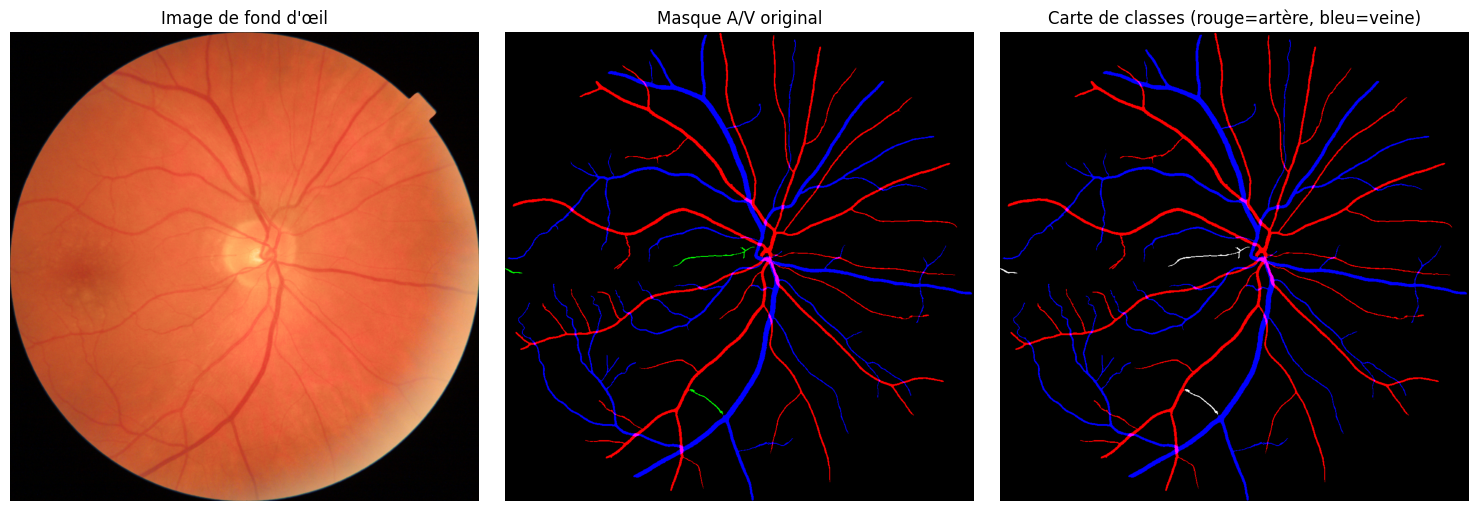

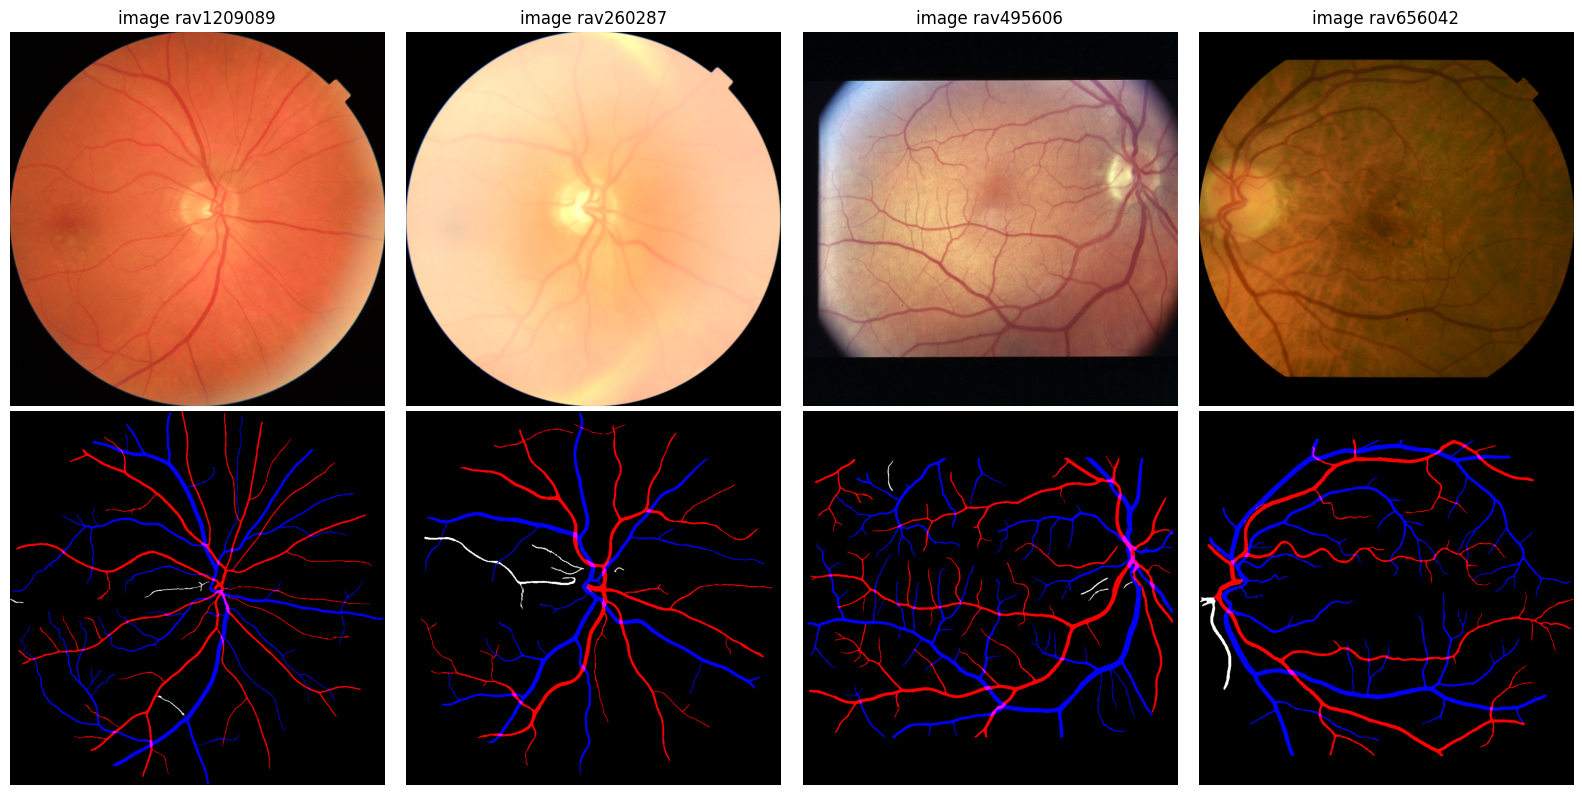


RÉSUMÉ ÉTAPE 1 (à copier-coller dans la conversation)
Dataset : Rotterdam RAV (https://dataverse.nl/dataset.xhtml?persistentId=doi:10.34894/9OIMWY)
Nombre de paires image/masque : 206
Tailles des images : {'1024x1024': 206}
Dossier images : /kaggle/working/retina_av/data/dataset/rgb
Dossier masques : /kaggle/working/retina_av/data/dataset/av_masks
Pourcentage moyen de pixels par classe :
   background : 93.087 %
   artery     : 3.066 %
   vein       : 3.538 %
   crossing   : 0.149 %
   unknown    : 0.160 %
Part de vaisseaux (toutes classes) : 6.91 %
Artères / veines (rapport de pixels) : 0.87
Images sans artère ou sans veine : aucune
Fichiers sauvegardés dans /kaggle/working/retina_av : dataset_stats.csv, fig_example.png, fig_grid.png, summary.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# =====================================================================
# Retina A/V segmentation – ÉTAPE 1 : tout est automatique
# (téléchargement du dataset Rotterdam RAV, détection des dossiers,
#  appariement images/masques, conversion des couleurs, statistiques, figures)
# Il suffit d'exécuter cette cellule (GPU non nécessaire pour cette étape).
# =====================================================================
import os, re, sys, json, time, shutil, zipfile, tarfile, urllib.parse
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from PIL import Image
Image.MAX_IMAGE_PIXELS = None

# ----------------------------- PARAMÈTRES ----------------------------
USE_DRIVE   = False                       # True = sauvegarde sur Google Drive (si le montage marche)
PROJECT_DIR = os.environ.get('RETINA_DIR', '/content/retina_av')
BASE        = 'https://dataverse.nl'
DOI         = 'doi:10.34894/9OIMWY'       # Rotterdam artery-vein (RAV) dataset
DATASET     = 'Rotterdam RAV'
GREEN_MEANS = 'unknown'                   # RAV : vert = inconnu ; mettre 'crossing' pour RITE
SKIP_DOWNLOAD = bool(os.environ.get('RETINA_SKIP_DL'))
SKIP_WORDS  = ('enhanc', 'contrast', 'clahe')   # versions pré-traitées : non téléchargées
# ---------------------------------------------------------------------

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        PROJECT_DIR = '/content/drive/MyDrive/retina_av'
    except Exception as e:
        print('Drive indisponible, stockage temporaire utilisé :', e)
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
os.makedirs(DATA_DIR, exist_ok=True)
print('Dossier du projet :', PROJECT_DIR)

# ------------------------- 1. TÉLÉCHARGEMENT -------------------------
HEAD = {'User-Agent': 'Mozilla/5.0 (retina-av-notebook)'}

def list_remote_files():
    r = requests.get(f'{BASE}/api/datasets/:persistentId/', params={'persistentId': DOI},
                     headers=HEAD, timeout=60)
    r.raise_for_status()
    files = r.json()['data']['latestVersion']['files']
    if not files:   # variante d'API plus récente
        r = requests.get(f'{BASE}/api/datasets/:persistentId/versions/:latest/files',
                         params={'persistentId': DOI, 'limit': 1000}, headers=HEAD, timeout=60)
        r.raise_for_status()
        files = r.json()['data']
    return files

def download(file_id, out, tries=3):
    for t in range(tries):
        try:
            with requests.get(f'{BASE}/api/access/datafile/{file_id}', headers=HEAD,
                              stream=True, timeout=180) as r:
                r.raise_for_status()
                with open(out + '.part', 'wb') as fh:
                    for chunk in r.iter_content(1 << 20):
                        fh.write(chunk)
            os.replace(out + '.part', out)
            return True
        except Exception as e:
            print('   nouvel essai', t + 1, '->', e)
            time.sleep(3)
    return False

def unpack_archives(root):
    for dp, _, fns in os.walk(root):
        for f in fns:
            p = os.path.join(dp, f)
            low = f.lower()
            if low.endswith(('.zip', '.tar', '.tar.gz', '.tgz')):
                dest = p + '_extracted'
                if os.path.isdir(dest):
                    continue
                try:
                    shutil.unpack_archive(p, dest)
                    print('décompressé :', f)
                except Exception as e:
                    print('impossible de décompresser', f, e)
                    shutil.rmtree(dest, ignore_errors=True)

if not SKIP_DOWNLOAD:
    print('\n[1/5] Téléchargement depuis', BASE, DOI)
    files = list_remote_files()
    print(len(files), 'fichiers dans le dépôt')
    todo = []
    for f in files:
        d, sub = f['dataFile'], f.get('directoryLabel', '')
        path = (sub + '/' + d['filename']).lower()
        if any(w in path for w in SKIP_WORDS):
            continue
        todo.append((d['id'], sub, d['filename']))
    print(len(todo), 'fichiers à télécharger (versions pré-traitées ignorées)')
    fails = 0
    for n, (fid, sub, name) in enumerate(todo, 1):
        out_dir = os.path.join(DATA_DIR, sub)
        os.makedirs(out_dir, exist_ok=True)
        out = os.path.join(out_dir, name)
        if not (os.path.exists(out) and os.path.getsize(out) > 0):
            if not download(fid, out):
                fails += 1
        if n % 25 == 0 or n == len(todo):
            print(f'   {n}/{len(todo)}')
    if fails:
        print(f'ATTENTION : {fails} fichier(s) non téléchargé(s). Relancez la cellule : seuls les manquants seront repris.')
    unpack_archives(DATA_DIR)
else:
    print('[1/5] Téléchargement ignoré (mode test)')

# ------------- 2. DÉTECTION AUTOMATIQUE IMAGES / MASQUES -------------
print('\n[2/5] Détection automatique des images et des masques A/V')
IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp', '.gif')

def scan(root):
    out = []
    for dp, _, fns in os.walk(root):
        if '__MACOSX' in dp:
            continue
        for f in fns:
            if f.lower().endswith(IMG_EXT) and not f.startswith('._'):
                out.append(os.path.join(dp, f))
    return sorted(out)

def classify(path):
    """image = photo (beaucoup de couleurs) ; av = masque coloré (peu de couleurs, saturées)."""
    try:
        im = Image.open(path).convert('RGB')
    except Exception:
        return 'bad'
    cols = im.getcolors(maxcolors=64)
    if cols is None:
        return 'image'
    arr = np.array([c for _, c in cols])
    return 'av' if ((arr.max(1) - arr.min(1)) > 100).any() else 'binary'

all_files = scan(DATA_DIR)
print(len(all_files), 'fichiers image trouvés')
kinds = {p: classify(p) for p in all_files}
imgs = [p for p, k in kinds.items() if k == 'image']
avs  = [p for p, k in kinds.items() if k == 'av']
print(f'  photos : {len(imgs)} | masques A/V colorés : {len(avs)} | masques binaires/autres : '
      f'{sum(k in ("binary", "bad") for k in kinds.values())}')

STOP = r'(av|a_v|mask|masks|label|labels|gt|seg|segmentation|artery|vein|arteries|veins|rgb|fundus|image|images|img|cfp|enhanced|contrast|clahe)'
def norm_key(p):
    s = os.path.splitext(os.path.basename(p))[0].lower()
    s = re.sub(r'(?<![a-z])' + STOP + r'(?![a-z])', '', s)
    return re.sub(r'[^a-z0-9]+', '', s)

def digits_key(p):
    nums = re.findall(r'\d+', os.path.basename(p))
    return '-'.join(str(int(n)) for n in nums)

def build_pairs(imgs, avs):
    pairs, used, dup = [], set(), 0
    def group(paths, keyf):
        d = {}
        for p in paths:
            if p not in used:
                d.setdefault(keyf(p), []).append(p)
        return d
    def pick(c):
        return sorted(c, key=lambda p: (any(w in p.lower() for w in SKIP_WORDS), p))[0]
    for keyf in (norm_key, digits_key):
        gi, ga = group(imgs, keyf), group(avs, keyf)
        for k in sorted(set(gi) & set(ga)):
            if not k:
                continue
            if len(gi[k]) > 1 or len(ga[k]) > 1:
                dup += 1
            pairs.append((k, pick(gi[k]), pick(ga[k])))
            used.update(gi[k]); used.update(ga[k])
    return pairs, dup

pairs, dup = build_pairs(imgs, avs)
print(len(pairs), 'paires image/masque trouvées')
if dup:
    print(f'  ({dup} identifiants avaient plusieurs candidats : le premier a été retenu)')
if not pairs:
    print('\nAucune paire. Dossiers contenant des images :')
    for d in sorted({os.path.dirname(p) for p in all_files}):
        print('  ', d)
    raise SystemExit('Aucune paire trouvée : copiez ce message, je corrige.')
print('Exemple :', pairs[0][1], '<->', pairs[0][2])
print('Dossier images :', os.path.dirname(pairs[0][1]))
print('Dossier masques:', os.path.dirname(pairs[0][2]))

# ----------------- 3. CONVERSION COULEURS -> CLASSES -----------------
print('\n[3/5] Conversion des masques couleur en classes')
CLASS_NAMES = {0: 'background', 1: 'artery', 2: 'vein', 3: 'crossing', 4: 'unknown'}
PALETTE = np.array([[0, 0, 0], [255, 0, 0], [0, 0, 255], [255, 0, 255], [255, 255, 255]], dtype=np.uint8)

def av_rgb_to_classes(rgb, thr=128):
    b = rgb >= thr
    R, G, B = b[..., 0], b[..., 1], b[..., 2]
    out = np.zeros(R.shape, np.uint8)
    out[R & ~G & ~B] = 1                      # rouge   = artère
    out[~R & ~G & B] = 2                      # bleu    = veine
    out[R & ~G & B] = 3                       # magenta = croisement (artère + veine)
    out[~R & G & ~B] = 3 if GREEN_MEANS == 'crossing' else 4   # vert
    out[R & G & B] = 4                        # blanc   = incertain
    out[(R & G & ~B) | (~R & G & B)] = 4      # jaune / cyan = autre
    return out

# auto-test
_t = np.zeros((1, 6, 3), np.uint8)
_t[0, 0] = [255, 0, 0]; _t[0, 1] = [0, 0, 255]; _t[0, 2] = [255, 0, 255]
_t[0, 3] = [255, 255, 255]; _t[0, 4] = [0, 255, 0]
print('auto-test (attendu [1 2 3 4 4 0]) :', av_rgb_to_classes(_t)[0])

def load_pair(pi, pa):
    img = np.array(Image.open(pi).convert('RGB'))
    av = np.array(Image.open(pa).convert('RGB'))
    return img, av_rgb_to_classes(av)

# recensement des couleurs réellement présentes (vérification automatique)
census = {}
for _, _, pa in pairs[:10]:
    for cnt, col in Image.open(pa).convert('RGB').getcolors(maxcolors=100000) or []:
        census[col] = census.get(col, 0) + cnt
tot = sum(census.values())
print('Couleurs les plus fréquentes dans les masques (10 premiers) :')
for col, cnt in sorted(census.items(), key=lambda x: -x[1])[:8]:
    c = int(av_rgb_to_classes(np.array([[col]], dtype=np.uint8))[0, 0])
    print(f'   RGB{col} : {100 * cnt / tot:6.2f} %  -> classe {c} ({CLASS_NAMES[c]})')
nonpure = sum(cnt for col, cnt in census.items() if any(v not in (0, 255) for v in col))
if nonpure / tot > 0.02:
    print(f'   ATTENTION : {100 * nonpure / tot:.1f} % des pixels ont des couleurs intermédiaires (lissage/compression).')

# ------------------------- 4. STATISTIQUES --------------------------
print('\n[4/5] Statistiques sur', len(pairs), 'images')
rows = []
for n, (k, pi, pa) in enumerate(pairs, 1):
    img, cls = load_pair(pi, pa)
    row = {'id': k, 'height': img.shape[0], 'width': img.shape[1]}
    for c, name in CLASS_NAMES.items():
        row[name + '_%'] = 100.0 * (cls == c).sum() / cls.size
    rows.append(row)
    if n % 50 == 0:
        print(f'   {n}/{len(pairs)}')
stats = pd.DataFrame(rows).set_index('id')
pct_cols = [c for c in stats.columns if c.endswith('_%')]
means = stats[pct_cols].mean()
sizes = stats.groupby(['height', 'width']).size()
no_av = stats[(stats['artery_%'] == 0) | (stats['vein_%'] == 0)].index.tolist()
vessel = means['artery_%'] + means['vein_%'] + means['crossing_%'] + means['unknown_%']
stats.round(3).to_csv(os.path.join(PROJECT_DIR, 'dataset_stats.csv'))

# --------------------------- 5. FIGURES -----------------------------
print('\n[5/5] Figures')
k, pi, pa = pairs[0]
img, cls = load_pair(pi, pa)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img); ax[0].set_title('Image de fond d\'œil')
ax[1].imshow(Image.open(pa).convert('RGB')); ax[1].set_title('Masque A/V original')
ax[2].imshow(PALETTE[cls]); ax[2].set_title('Carte de classes (rouge=artère, bleu=veine)')
for a in ax: a.axis('off')
plt.tight_layout(); fig.savefig(os.path.join(PROJECT_DIR, 'fig_example.png'), dpi=120); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for j in range(4):
    k, pi, pa = pairs[min(j * max(len(pairs) // 4, 1), len(pairs) - 1)]
    img, cls = load_pair(pi, pa)
    ax[0, j].imshow(img); ax[0, j].set_title(f'image {k}')
    ax[1, j].imshow(PALETTE[cls])
    ax[0, j].axis('off'); ax[1, j].axis('off')
plt.tight_layout(); fig.savefig(os.path.join(PROJECT_DIR, 'fig_grid.png'), dpi=100); plt.show()

# ------------------------- RÉSUMÉ À ENVOYER -------------------------
summary = [
    '=' * 60,
    'RÉSUMÉ ÉTAPE 1 (à copier-coller dans la conversation)',
    '=' * 60,
    f'Dataset : {DATASET} ({BASE}/dataset.xhtml?persistentId={DOI})',
    f'Nombre de paires image/masque : {len(pairs)}',
    f'Tailles des images : {dict((f"{h}x{w}", int(c)) for (h, w), c in sizes.items())}',
    f'Dossier images : {os.path.dirname(pairs[0][1])}',
    f'Dossier masques : {os.path.dirname(pairs[0][2])}',
    'Pourcentage moyen de pixels par classe :',
] + [f'   {c.replace("_%", ""):<11}: {means[c]:.3f} %' for c in pct_cols] + [
    f'Part de vaisseaux (toutes classes) : {vessel:.2f} %',
    f'Artères / veines (rapport de pixels) : {means["artery_%"] / max(means["vein_%"], 1e-9):.2f}',
    f'Images sans artère ou sans veine : {no_av if no_av else "aucune"}',
    f'Fichiers sauvegardés dans {PROJECT_DIR} : dataset_stats.csv, fig_example.png, fig_grid.png, summary.txt',
]
text = '\n'.join(summary)
print('\n' + text)
with open(os.path.join(PROJECT_DIR, 'summary.txt'), 'w') as fh:
    fh.write(text)

try:   # téléchargement automatique des résultats vers votre ordinateur (Colab)
    from google.colab import files
    for f in ('summary.txt', 'dataset_stats.csv', 'fig_example.png', 'fig_grid.png'):
        files.download(os.path.join(PROJECT_DIR, f))
except Exception:
    pass


## Étape 2 – Pipeline de données
**Ce que fait la cellule**
- met les images et les labels en cache (tableaux numpy) ; croisements et vaisseaux inconnus reçoivent l'étiquette 255, **ignorée par la perte** : il reste 3 classes (fond, artère, veine) ;
- sépare en train / validation / test **par image** (70/15/15 %, graine 42), avec un contrôle automatique qu'aucune image n'est dans deux ensembles ;
- tire des patches 256×256 centrés sur un vaisseau dans 70 % des cas (échantillonnage équilibré) ;
- augmentation : retournements, rotations de 90°, gamma, contraste/luminosité, gain par canal ; validation et test sur images entières sans augmentation ;
- normalisation par canal dans le champ de vue ; crée les DataLoaders PyTorch et enregistre `pipeline.py`, `split.json`, `pipeline_config.json`.

**Résultats obtenus** : train 144 / val 31 / test 31 ; fréquences images entières [93,48 ; 3,01 ; 3,51] %, patches tirés [90,1 ; 4,6 ; 5,3] % ; poids de classe [0,256 ; 1,424 ; 1,32].

Images : /kaggle/working/retina_av/data/dataset/rgb 
Masques: /kaggle/working/retina_av/data/dataset/av_masks

[1/4] Construction du cache (1 à 3 minutes)
206 images en cache | forme images (206, 1024, 1024, 3) | labels (206, 1024, 1024)

[2/4] Séparation train / val / test par image (graine 42 )
{'train': 144, 'val': 31, 'test': 31}

[3/4] Contrôles du pipeline
patch : x (3, 256, 256) float32, y (256, 256) int64 | valeurs de y : [0, 1, 2]
vitesse : 74 patches/s (un seul processus)
Fréquences (fond/artère/veine) images entières : [93.48  3.01  3.51] % | ignoré 0.31 %
Fréquences (fond/artère/veine) patches tirés    : [89.76  4.68  5.56] % | ignoré 0.52 %
Poids de classe suggérés (1/sqrt(freq), somme=3): [0.256 1.424 1.32 ]


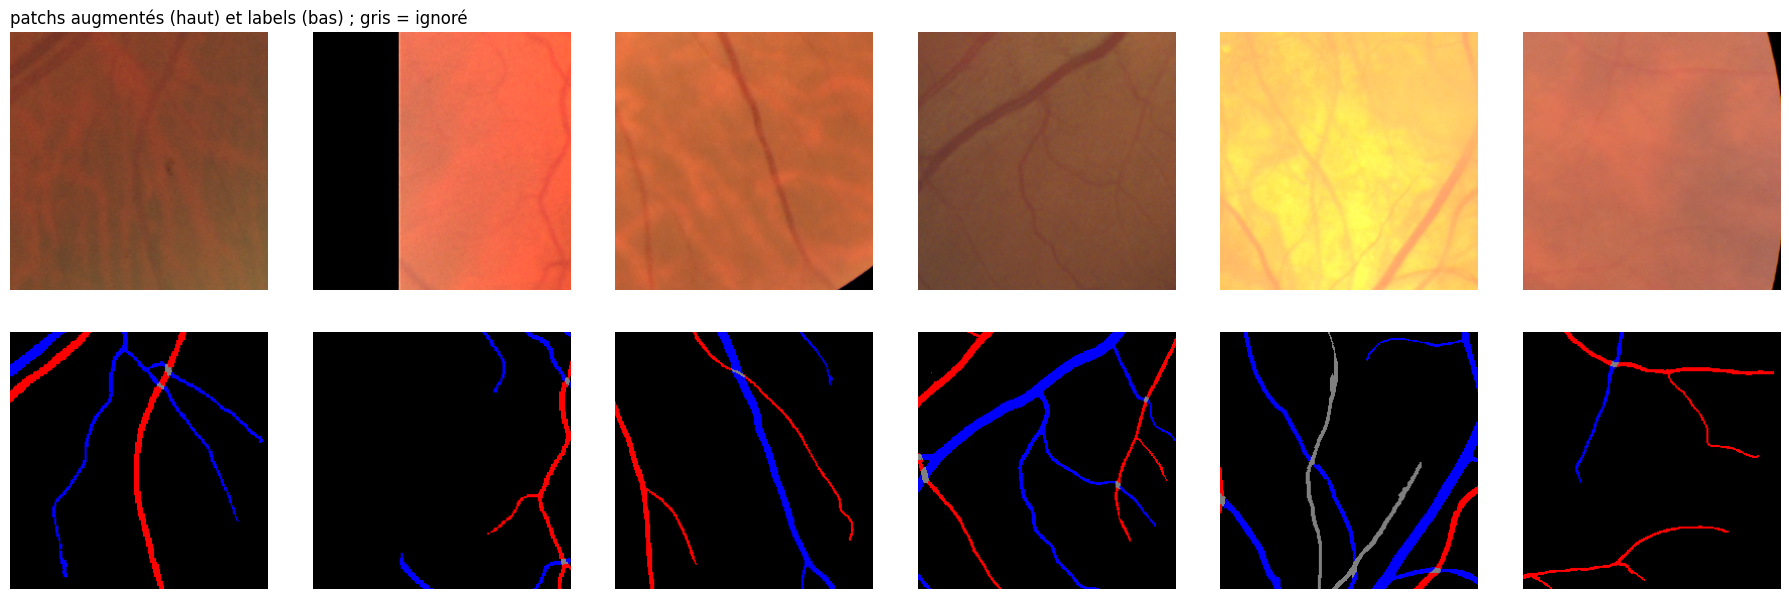


[4/4] DataLoaders PyTorch
batch train : (8, 3, 256, 256) (8, 256, 256) | image val : (1, 3, 1024, 1024) (1, 1024, 1024)
GPU disponible : True

RÉSUMÉ ÉTAPE 2 (à copier-coller dans la conversation)
Images en cache : 206 de taille 1024x1024
Séparation par image : {'train': 144, 'val': 31, 'test': 31} (graine 42)
Patches : 256x256, 1152 par époque, batch 8, p_vessel=0.7
Vitesse : 74 patches/s (1 processus)
Fréquences images entières (fond/artère/veine, %) : [93.48, 3.01, 3.51] ; ignoré 0.31 %
Fréquences patches tirés (fond/artère/veine, %)    : [89.76, 4.68, 5.56] ; ignoré 0.52 %
Poids de classe suggérés : [0.256, 1.424, 1.32]
Fichiers : split.json, pipeline.py, pipeline_config.json, fig_patches.png, cache/


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# =====================================================================
# Retina A/V segmentation – ÉTAPE 2 : pipeline de données (automatique)
# Cache des données, séparation train/val/test PAR IMAGE, patches centrés
# sur les vaisseaux, augmentation, DataLoaders PyTorch, figure de contrôle.
# Prérequis : l'étape 1 a été exécutée (les données sont dans /content/retina_av).
# =====================================================================
import os, sys, json, time, glob, importlib
import numpy as np
from PIL import Image
Image.MAX_IMAGE_PIXELS = None

# ----------------------------- PARAMÈTRES ----------------------------
PROJECT_DIR = os.environ.get('RETINA_DIR', '/content/retina_av')
SEED        = 42
SPLIT       = (0.70, 0.15, 0.15)     # train / val / test (par image)
PATCH       = int(os.environ.get('RETINA_PATCH', 256))   # taille des patches d'entraînement
PATCHES_PER_EPOCH = 1152             # patches tirés par époque (train)
BATCH       = 8
P_VESSEL    = 0.7                    # proba de centrer un patch sur un vaisseau
# ---------------------------------------------------------------------
CACHE = os.path.join(PROJECT_DIR, 'cache'); os.makedirs(CACHE, exist_ok=True)

# ------------------- 1. LOCALISER LES DOSSIERS -----------------------
def find_dir(name):
    for dp, dn, _ in os.walk(os.path.join(PROJECT_DIR, 'data')):
        if os.path.basename(dp) == name and 'MACOSX' not in dp:
            return dp
    return None
IMG_DIR, AV_DIR = find_dir('rgb'), find_dir('av_masks')
if not (IMG_DIR and AV_DIR):
    raise SystemExit("Dossiers 'rgb' / 'av_masks' introuvables : exécutez d'abord l'étape 1 (le stockage Colab est effacé entre sessions).")
print('Images :', IMG_DIR, '\nMasques:', AV_DIR)

# ------------- 2. CACHE NUMPY (images + labels 0/1/2/255) -----------
IGNORE = 255
def av_rgb_to_train_labels(rgb, thr=128):
    """0 fond, 1 artère, 2 veine ; croisements et vaisseaux inconnus -> 255 (ignorés par la perte)."""
    b = rgb >= thr
    R, G, B = b[..., 0], b[..., 1], b[..., 2]
    out = np.zeros(R.shape, np.uint8)
    out[R & ~G & ~B] = 1
    out[~R & ~G & B] = 2
    out[(R & B) | G] = IGNORE          # magenta (croisement), vert, jaune, cyan, blanc
    return out

names_path = os.path.join(CACHE, 'names.json')
if all(os.path.exists(os.path.join(CACHE, f)) for f in ('images.npy', 'labels.npy', 'names.json')):
    print('\n[1/4] Cache trouvé, chargement')
    names = json.load(open(names_path))
else:
    print('\n[1/4] Construction du cache (1 à 3 minutes)')
    stems = sorted(os.path.splitext(f)[0] for f in os.listdir(AV_DIR) if f.lower().endswith(('.png', '.tif', '.jpg')))
    img_ext = {os.path.splitext(f)[0]: f for f in os.listdir(IMG_DIR)}
    names = [s for s in stems if s in img_ext]
    av_ext = {os.path.splitext(f)[0]: f for f in os.listdir(AV_DIR)}
    first = np.array(Image.open(os.path.join(IMG_DIR, img_ext[names[0]])).convert('RGB'))
    H, W = first.shape[:2]
    images = np.lib.format.open_memmap(os.path.join(CACHE, 'images.npy'), 'w+', np.uint8, (len(names), H, W, 3))
    labels = np.lib.format.open_memmap(os.path.join(CACHE, 'labels.npy'), 'w+', np.uint8, (len(names), H, W))
    for n, s in enumerate(names):
        im = np.array(Image.open(os.path.join(IMG_DIR, img_ext[s])).convert('RGB'))
        av = np.array(Image.open(os.path.join(AV_DIR, av_ext[s])).convert('RGB'))
        assert im.shape[:2] == av.shape[:2] == (H, W), f'tailles différentes pour {s}'
        images[n], labels[n] = im, av_rgb_to_train_labels(av)
    images.flush(); labels.flush(); del images, labels
    json.dump(names, open(names_path, 'w'))
images = np.load(os.path.join(CACHE, 'images.npy'), mmap_mode='r')
labels = np.load(os.path.join(CACHE, 'labels.npy'), mmap_mode='r')
print(len(names), 'images en cache | forme images', images.shape, '| labels', labels.shape)

# ------------------- 3. SÉPARATION PAR IMAGE -------------------------
print('\n[2/4] Séparation train / val / test par image (graine', SEED, ')')
rng = np.random.default_rng(SEED)
order = rng.permutation(len(names))
n_tr = int(round(SPLIT[0] * len(names))); n_va = int(round(SPLIT[1] * len(names)))
split = {'train': sorted(order[:n_tr].tolist()),
         'val':   sorted(order[n_tr:n_tr + n_va].tolist()),
         'test':  sorted(order[n_tr + n_va:].tolist())}
assert not (set(split['train']) & set(split['val'])) and not (set(split['train']) & set(split['test'])) \
    and not (set(split['val']) & set(split['test'])), 'fuite entre les ensembles !'
print({k: len(v) for k, v in split.items()})
json.dump({'seed': SEED, 'names': names, 'split': split,
           'split_names': {k: [names[i] for i in v] for k, v in split.items()}},
          open(os.path.join(PROJECT_DIR, 'split.json'), 'w'), indent=1)

# ------------------- 4. MODULE pipeline.py (réutilisé étape 3) ------
PIPELINE_SRC = r'''
import numpy as np
IGNORE = 255

def normalize(img01):
    """img01 : HxWx3 float [0,1] -> 3xHxW standardisé par canal (statistiques calculées dans le champ de vue)."""
    fov = img01.max(axis=2) > 0.04
    px = img01[fov] if fov.sum() > 100 else img01.reshape(-1, 3)
    mean, std = px.mean(0), px.std(0) + 1e-6
    return np.ascontiguousarray(((img01 - mean) / std).transpose(2, 0, 1), dtype=np.float32)

class PatchSampler:
    """Patches d'entraînement : centrés sur un vaisseau avec proba p_vessel, + augmentation."""
    def __init__(self, images, labels, indices, size=256, length=1000, p_vessel=0.7, seed=None):
        self.images, self.labels, self.idx = images, labels, list(indices)
        self.size, self.length, self.p_vessel, self.seed = size, length, p_vessel, seed
        r = np.random.default_rng(0)
        self.vessel = {}
        for i in self.idx:
            m = np.argwhere((np.asarray(labels[i]) == 1) | (np.asarray(labels[i]) == 2))
            if len(m) > 20000:
                m = m[r.choice(len(m), 20000, replace=False)]
            self.vessel[i] = m
    def __len__(self):
        return self.length
    def _make(self, k):
        rng = np.random.default_rng() if self.seed is None else np.random.default_rng([self.seed, k])
        i = self.idx[int(rng.integers(len(self.idx)))]
        H, W = self.labels[i].shape; s = self.size
        if rng.random() < self.p_vessel and len(self.vessel[i]):
            cy, cx = self.vessel[i][int(rng.integers(len(self.vessel[i])))]
            j = s // 4
            y0 = int(np.clip(cy - s // 2 + rng.integers(-j, j + 1), 0, H - s))
            x0 = int(np.clip(cx - s // 2 + rng.integers(-j, j + 1), 0, W - s))
        else:
            y0, x0 = int(rng.integers(0, H - s + 1)), int(rng.integers(0, W - s + 1))
        img = np.asarray(self.images[i][y0:y0 + s, x0:x0 + s]).astype(np.float32) / 255.0
        lab = np.asarray(self.labels[i][y0:y0 + s, x0:x0 + s]).copy()
        if rng.random() < 0.5: img, lab = img[:, ::-1], lab[:, ::-1]
        if rng.random() < 0.5: img, lab = img[::-1], lab[::-1]
        r90 = int(rng.integers(4)); img, lab = np.rot90(img, r90), np.rot90(lab, r90)
        img = np.clip(img, 0, 1) ** rng.uniform(0.8, 1.25)                 # gamma
        img = (img - 0.5) * rng.uniform(0.8, 1.2) + 0.5 + rng.uniform(-0.1, 0.1)   # contraste / luminosité
        img = np.clip(img * rng.uniform(0.9, 1.1, size=3), 0, 1)           # gain par canal
        return np.ascontiguousarray(img, dtype=np.float32), np.ascontiguousarray(lab)
    def get(self, k):
        img, lab = self._make(k)
        return normalize(img), lab.astype(np.int64)
    def get_raw(self, k):
        img, lab = self._make(k)
        return (img * 255).astype(np.uint8), lab

class FullSampler:
    """Images entières (validation / test), sans augmentation."""
    def __init__(self, images, labels, indices):
        self.images, self.labels, self.idx = images, labels, list(indices)
    def __len__(self):
        return len(self.idx)
    def get(self, k):
        i = self.idx[k]
        img = np.asarray(self.images[i]).astype(np.float32) / 255.0
        return normalize(img), np.asarray(self.labels[i]).astype(np.int64)

try:
    import torch
    from torch.utils.data import Dataset
    class RetinaPatches(PatchSampler, Dataset):
        def __getitem__(self, k):
            x, y = self.get(k); return torch.from_numpy(x), torch.from_numpy(y)
    class RetinaFull(FullSampler, Dataset):
        def __getitem__(self, k):
            x, y = self.get(k); return torch.from_numpy(x), torch.from_numpy(y)
except ImportError:
    pass
'''
open(os.path.join(PROJECT_DIR, 'pipeline.py'), 'w').write(PIPELINE_SRC)
sys.path.insert(0, PROJECT_DIR)
import pipeline; importlib.reload(pipeline)

# ------------------- 5. CONTRÔLES --------------------------------------
print('\n[3/4] Contrôles du pipeline')
train_ps = pipeline.PatchSampler(images, labels, split['train'], PATCH, PATCHES_PER_EPOCH, P_VESSEL)
t0 = time.time(); xs, ys = zip(*[train_ps.get(k) for k in range(64)]); dt = time.time() - t0
x, y = xs[0], ys[0]
print(f'patch : x {x.shape} {x.dtype}, y {y.shape} {y.dtype} | valeurs de y : {np.unique(y).tolist()}')
print(f'vitesse : {64 / dt:.0f} patches/s (un seul processus)')

# fréquences des classes : images entières (train) vs patches échantillonnés
tr_lab = np.concatenate([np.asarray(labels[i]).ravel()[::16] for i in split['train']])
def freq(a):
    valid = a[a != IGNORE]
    return np.array([(valid == c).mean() for c in (0, 1, 2)]), (a == IGNORE).mean()
f_img, ig_img = freq(tr_lab)
sample = np.concatenate([train_ps.get(k)[1].ravel() for k in range(300)])
f_pat, ig_pat = freq(sample)
w = 1.0 / np.sqrt(f_img); w = w / w.sum() * 3          # poids suggérés pour l'entropie croisée (étape 3)
print('Fréquences (fond/artère/veine) images entières :', np.round(100 * f_img, 2), '% | ignoré', round(100 * ig_img, 2), '%')
print('Fréquences (fond/artère/veine) patches tirés    :', np.round(100 * f_pat, 2), '% | ignoré', round(100 * ig_pat, 2), '%')
print('Poids de classe suggérés (1/sqrt(freq), somme=3):', np.round(w, 3))
json.dump({'class_freq_full_train': f_img.tolist(), 'class_weights': w.tolist(), 'patch': PATCH, 'batch': BATCH},
          open(os.path.join(PROJECT_DIR, 'pipeline_config.json'), 'w'))

# ------------------- 6. FIGURE ------------------------------------------
import matplotlib.pyplot as plt
PAL = np.array([[0, 0, 0], [255, 0, 0], [0, 0, 255]], dtype=np.uint8)
def colorize(lab):
    out = np.zeros(lab.shape + (3,), np.uint8)
    for c in (0, 1, 2): out[lab == c] = PAL[c]
    out[lab == IGNORE] = (128, 128, 128)
    return out
fig, ax = plt.subplots(2, 6, figsize=(18, 6.5))
for j in range(6):
    im, lb = train_ps.get_raw(j)
    ax[0, j].imshow(im); ax[1, j].imshow(colorize(lb)); ax[0, j].axis('off'); ax[1, j].axis('off')
ax[0, 0].set_title('patchs augmentés (haut) et labels (bas) ; gris = ignoré', loc='left')
plt.tight_layout(); fig.savefig(os.path.join(PROJECT_DIR, 'fig_patches.png'), dpi=100); plt.show()

# ------------------- 7. DATALOADERS PYTORCH ----------------------------
print('\n[4/4] DataLoaders PyTorch')
try:
    import torch
    from torch.utils.data import DataLoader
    train_ds = pipeline.RetinaPatches(images, labels, split['train'], PATCH, PATCHES_PER_EPOCH, P_VESSEL)
    val_ds, test_ds = pipeline.RetinaFull(images, labels, split['val']), pipeline.RetinaFull(images, labels, split['test'])
    train_loader = DataLoader(train_ds, batch_size=BATCH, num_workers=2, pin_memory=True, persistent_workers=True)
    val_loader = DataLoader(val_ds, batch_size=1, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=1, num_workers=0)
    xb, yb = next(iter(train_loader)); xv, yv = next(iter(val_loader))
    print('batch train :', tuple(xb.shape), tuple(yb.shape), '| image val :', tuple(xv.shape), tuple(yv.shape))
    print('GPU disponible :', torch.cuda.is_available())
except Exception as e:
    print('PyTorch non utilisable ici :', e)

summary = '\n'.join([
    '=' * 60, 'RÉSUMÉ ÉTAPE 2 (à copier-coller dans la conversation)', '=' * 60,
    f'Images en cache : {len(names)} de taille {images.shape[1]}x{images.shape[2]}',
    f'Séparation par image : { {k: len(v) for k, v in split.items()} } (graine {SEED})',
    f'Patches : {PATCH}x{PATCH}, {PATCHES_PER_EPOCH} par époque, batch {BATCH}, p_vessel={P_VESSEL}',
    f'Vitesse : {64 / dt:.0f} patches/s (1 processus)',
    f'Fréquences images entières (fond/artère/veine, %) : {np.round(100 * f_img, 2).tolist()} ; ignoré {100 * ig_img:.2f} %',
    f'Fréquences patches tirés (fond/artère/veine, %)    : {np.round(100 * f_pat, 2).tolist()} ; ignoré {100 * ig_pat:.2f} %',
    f'Poids de classe suggérés : {np.round(w, 3).tolist()}',
    'Fichiers : split.json, pipeline.py, pipeline_config.json, fig_patches.png, cache/'])
print('\n' + summary)
open(os.path.join(PROJECT_DIR, 'summary_step2.txt'), 'w').write(summary)
try:
    from google.colab import files
    for f in ('summary_step2.txt', 'fig_patches.png', 'split.json'):
        files.download(os.path.join(PROJECT_DIR, f))
except Exception:
    pass


## Étape 3 – U-Net 2D à 3 classes (modèle de référence, 31 M de paramètres)
**Ce que fait la cellule**
- U-Net classique : 64 canaux de base, 4 niveaux, BatchNorm, 31,04 M de paramètres ;
- perte = entropie croisée pondérée + (1 − Dice moyen artère/veine), pixels ignorés exclus ;
- AdamW (lr 1e-3, décroissance cosinus), 60 époques, précision mixte, batch 8 ;
- protections contre les valeurs NaN (v2) : plancher sur l'écart-type, lots défectueux ignorés, statistiques BatchNorm restaurées, gradient écrêté ;
- le meilleur modèle est choisi sur la **validation** ; le **test** n'est utilisé qu'à la fin ;
- mesure du CO₂ avec CodeCarbon, temps d'inférence, Dice par classe (agrégé et par image).

**Résultats obtenus (jeu de test, 31 images)** : Dice artère 0,760 ; veine 0,777 ; vaisseau 0,852 ; fond 0,988. Par image : artère 0,754 ± 0,133, veine 0,783 ± 0,125. Meilleure époque : 52. Entraînement 40,1 min, 15,49 g CO₂eq, 0,0530 kWh, 148 ms par image 1024×1024.

*Un nouvel entraînement donnera des valeurs proches mais pas identiques : prenez celles de votre dernier run pour le CV.*

GPU : Tesla T4
unet_c64 : base=64, profondeur=4, 31.04 M paramètres


[codecarbon WARNING @ 18:36:09] Multiple instances of codecarbon are allowed to run at the same time.



Entraînement : 60 époques, 144 itérations/époque, batch 8, patch 256
ép   2 | perte 1.1471 | val Dice artère 0.377 veine 0.562 vaisseau 0.734 | 30s *
ép   4 | perte 1.0223 | val Dice artère 0.486 veine 0.626 vaisseau 0.806 | 34s *
ép   6 | perte 0.9357 | val Dice artère 0.541 veine 0.542 vaisseau 0.794 | 34s
ép   8 | perte 0.8848 | val Dice artère 0.582 veine 0.646 vaisseau 0.835 | 33s *
ép  10 | perte 0.8596 | val Dice artère 0.610 veine 0.682 vaisseau 0.841 | 33s *
ép  12 | perte 0.8221 | val Dice artère 0.613 veine 0.594 vaisseau 0.811 | 33s
ép  14 | perte 0.7439 | val Dice artère 0.632 veine 0.672 vaisseau 0.838 | 33s *
ép  16 | perte 0.7158 | val Dice artère 0.644 veine 0.702 vaisseau 0.852 | 33s *
ép  18 | perte 0.7198 | val Dice artère 0.677 veine 0.708 vaisseau 0.843 | 33s *
ép  20 | perte 0.6900 | val Dice artère 0.670 veine 0.742 vaisseau 0.861 | 33s *
ép  22 | perte 0.6564 | val Dice artère 0.694 veine 0.741 vaisseau 0.856 | 33s *
ép  24 | perte 0.6634 | val Dice artère 0.6

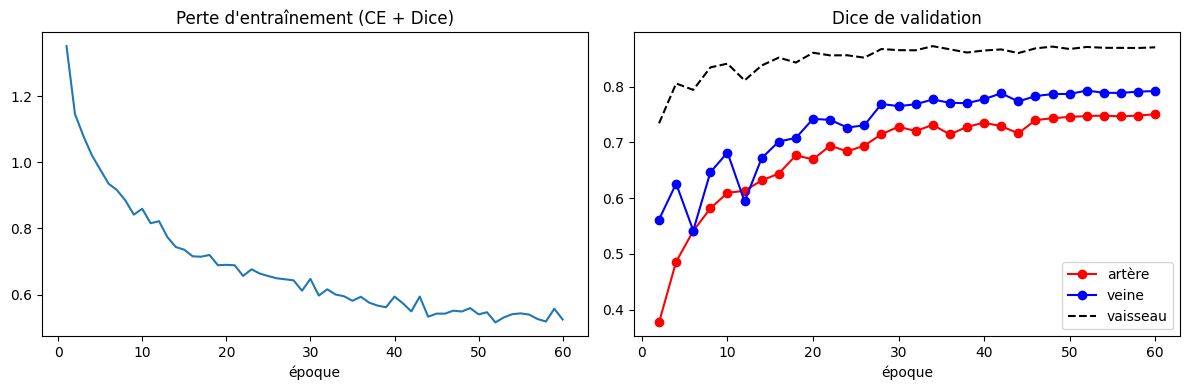

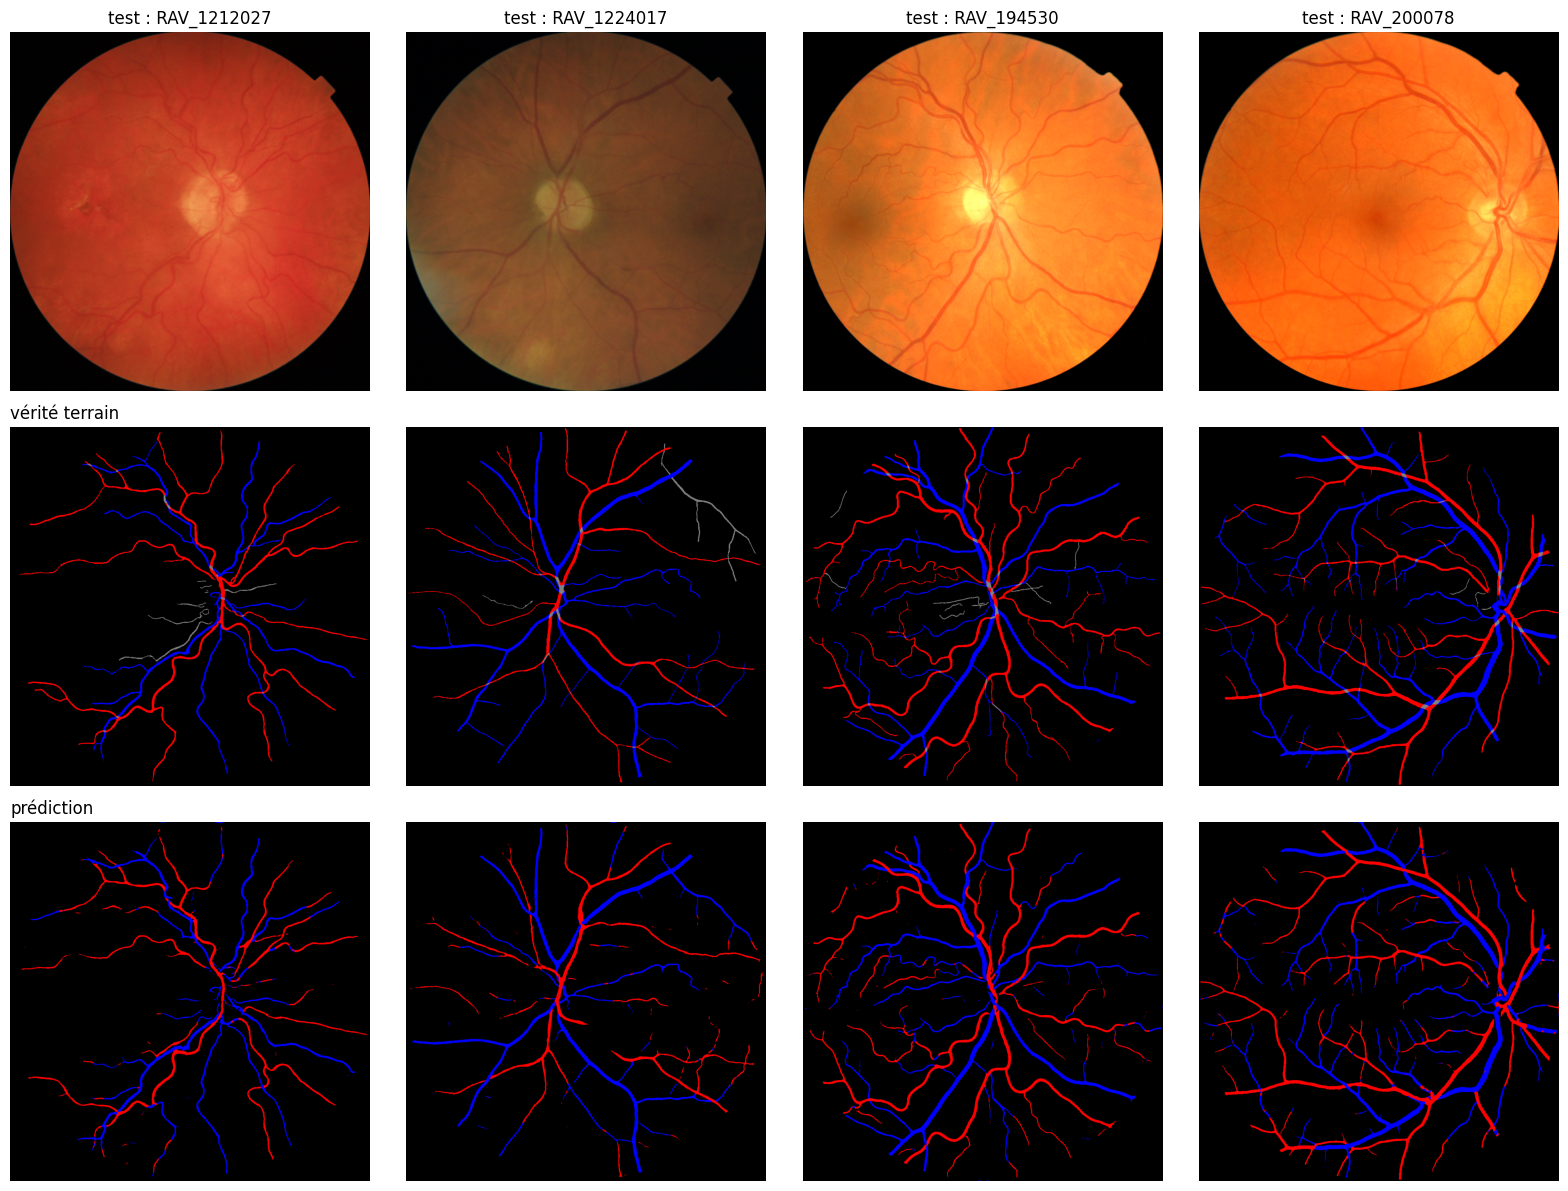


RÉSUMÉ ÉTAPE 3 – unet_c64 (à copier-coller dans la conversation)
GPU : Tesla T4 | paramètres : 31.04 M | époques : 60
Temps d'entraînement : 37.8 min | inférence : 147 ms / image 1024x1024
Émissions CodeCarbon : 17.44 gCO2eq, 0.0606 kWh
Meilleur Dice val (moyenne artère/veine) : 0.771 à l'époque 60 | lots défectueux ignorés : 0
TEST (agrégé)  Dice artère 0.764 | veine 0.785 | vaisseau 0.856 | fond 0.989
TEST (par image) artère 0.760 ± 0.125 | veine 0.788 ± 0.121 | vaisseau 0.857 ± 0.120
Fichiers : models/unet_c64.pt, results_unet_c64.json, history_unet_c64.csv, pred_test_unet_c64.npy, figures


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# =====================================================================
# Retina A/V segmentation – ÉTAPE 3 : U-Net 2D à 3 classes (fond, artère, veine)
# Perte entropie croisée + Dice, Dice par classe, mesure carbone (CodeCarbon),
# sauvegarde du meilleur modèle, prédictions du jeu de test, figures.
# Prérequis : étapes 1 et 2 exécutées dans la même session + GPU activé.
# =====================================================================
import os, sys, json, time, subprocess, importlib
import numpy as np

# ----------------------------- PARAMÈTRES ----------------------------
PROJECT_DIR = os.environ.get('RETINA_DIR', '/content/retina_av')
MODEL_NAME  = 'unet_c64'     # nom du modèle (sert aux fichiers de résultats)
BASE        = 64             # nombre de canaux de la 1re couche (U-Net classique = 64)
DEPTH       = 4              # nombre de niveaux de réduction
EPOCHS      = 60
LR          = 1e-3
VAL_EVERY   = 2              # validation toutes les N époques
SEED        = 42
# ---------------------------------------------------------------------

# ---------------------- métriques (numpy, sans torch) ----------------
def dice_from_conf(conf):
    """conf[vrai, prédit] 3x3 -> Dice par classe + Dice 'vaisseau' (artère ∪ veine vs fond)."""
    d = {}
    for c, name in ((0, 'background'), (1, 'artery'), (2, 'vein')):
        tp = conf[c, c]; fp = conf[:, c].sum() - tp; fn = conf[c, :].sum() - tp
        d[name] = float(2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) > 0 else float('nan')
    tp = conf[1:, 1:].sum(); fp = conf[0, 1:].sum(); fn = conf[1:, 0].sum()
    d['vessel'] = float(2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) > 0 else float('nan')
    d['mean_av'] = (d['artery'] + d['vein']) / 2
    return d

def conf_matrix(y_true, y_pred):
    v = y_true != 255
    return np.bincount(y_true[v].astype(np.int64) * 3 + y_pred[v].astype(np.int64), minlength=9).reshape(3, 3)

if os.environ.get('RETINA_METRICS_ONLY'):
    _y = np.array([[0, 1, 2, 255]]); _p = np.array([[0, 1, 1, 2]])
    print(conf_matrix(_y, _p)); print(dice_from_conf(conf_matrix(_y, _p))); sys.exit()

# ------------------------- préparation -------------------------------
try:
    import codecarbon
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'codecarbon'], check=False)
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader

assert torch.cuda.is_available(), "GPU non activé : menu Exécution > Modifier le type d'exécution > GPU T4, puis relancez les étapes 1 et 2 si la session a été réinitialisée."
device = 'cuda'
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
print('GPU :', torch.cuda.get_device_name(0))

CACHE = os.path.join(PROJECT_DIR, 'cache')
sys.path.insert(0, PROJECT_DIR)
import pipeline; importlib.reload(pipeline)
def _normalize(img01):
    """Standardisation par canal dans le champ de vue, avec plancher sur l'écart-type (évite les valeurs géantes)."""
    fov = img01.max(axis=2) > 0.04
    px = img01[fov] if fov.sum() > 100 else img01.reshape(-1, 3)
    mean, std = px.mean(0), np.maximum(px.std(0), 0.02)
    return np.ascontiguousarray(((img01 - mean) / std).transpose(2, 0, 1), dtype=np.float32)
pipeline.normalize = _normalize
cfg = json.load(open(os.path.join(PROJECT_DIR, 'pipeline_config.json')))
sp = json.load(open(os.path.join(PROJECT_DIR, 'split.json')))
split = sp['split']
images = np.load(os.path.join(CACHE, 'images.npy'), mmap_mode='r')
labels = np.load(os.path.join(CACHE, 'labels.npy'), mmap_mode='r')
PATCH, BATCH, CLASS_W = cfg['patch'], cfg['batch'], cfg['class_weights']

train_ds = pipeline.RetinaPatches(images, labels, split['train'], PATCH, 1152, 0.7)
val_ds   = pipeline.RetinaFull(images, labels, split['val'])
test_ds  = pipeline.RetinaFull(images, labels, split['test'])
train_loader = DataLoader(train_ds, batch_size=BATCH, num_workers=2, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val_ds, batch_size=1, num_workers=0)
test_loader  = DataLoader(test_ds, batch_size=1, num_workers=0)

# ------------------------------ modèle -------------------------------
class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, n_classes=3, base=64, depth=4):
        super().__init__()
        chs = [base * 2 ** i for i in range(depth + 1)]
        self.inc = DoubleConv(in_ch, chs[0])
        self.downs = nn.ModuleList([DoubleConv(chs[i], chs[i + 1]) for i in range(depth)])
        self.ups = nn.ModuleList([nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in reversed(range(depth))])
        self.dec = nn.ModuleList([DoubleConv(chs[i] * 2, chs[i]) for i in reversed(range(depth))])
        self.out = nn.Conv2d(chs[0], n_classes, 1)
    def forward(self, x):
        skips = [self.inc(x)]
        for d in self.downs:
            skips.append(d(F.max_pool2d(skips[-1], 2)))
        x = skips.pop()
        for up, dec in zip(self.ups, self.dec):
            x = up(x)
            x = dec(torch.cat([skips.pop(), x], 1))
        return self.out(x)

model = UNet(3, 3, BASE, DEPTH).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'{MODEL_NAME} : base={BASE}, profondeur={DEPTH}, {n_params / 1e6:.2f} M paramètres')
assert model(torch.zeros(1, 3, 64, 64, device=device)).shape == (1, 3, 64, 64)

# ------------------------------ perte --------------------------------
ce_w = torch.tensor(CLASS_W, dtype=torch.float32, device=device)
def dice_ce_loss(logits, y):
    ce = F.cross_entropy(logits.float(), y, weight=ce_w, ignore_index=255)
    valid = (y != 255)
    yy = y.clone(); yy[~valid] = 0
    prob = torch.softmax(logits.float(), 1)
    onehot = F.one_hot(yy, 3).permute(0, 3, 1, 2).float()
    m = valid.unsqueeze(1).float()
    prob, onehot = prob * m, onehot * m
    inter = (prob * onehot).sum((0, 2, 3)); den = prob.sum((0, 2, 3)) + onehot.sum((0, 2, 3))
    dice = (2 * inter + 1.0) / (den + 1.0)
    return ce + (1.0 - dice[1:].mean()), ce      # Dice sur artère et veine

# ---------------------------- évaluation -----------------------------
@torch.no_grad()
def evaluate(loader, keep_preds=False):
    model.eval()
    conf = np.zeros((3, 3), np.int64); confs, preds = [], []
    for x, y in loader:
        with torch.autocast('cuda', dtype=torch.float16):
            out = model(x.to(device, non_blocking=True))
        if not torch.isfinite(out).all():
            print('   ATTENTION : sorties non finies (NaN/inf) pendant l\'évaluation')
        p = out.argmax(1).cpu().numpy().astype(np.uint8); yn = y.numpy()
        for pi, yi in zip(p, yn):
            c = conf_matrix(yi, pi); conf += c; confs.append(c)
            if keep_preds: preds.append(pi)
    return conf, confs, preds

# ---------------------------- entraînement ---------------------------
os.makedirs(os.path.join(PROJECT_DIR, 'models'), exist_ok=True)
ckpt = os.path.join(PROJECT_DIR, 'models', MODEL_NAME + '.pt')
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
total_steps = EPOCHS * len(train_loader)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total_steps, eta_min=1e-5)
scaler = torch.amp.GradScaler('cuda')

tracker = None
try:
    from codecarbon import EmissionsTracker
    tracker = EmissionsTracker(project_name=MODEL_NAME, measure_power_secs=10, save_to_file=False, log_level='error')
    tracker.start()
except Exception as e:
    print('CodeCarbon indisponible :', e)

print(f'\nEntraînement : {EPOCHS} époques, {len(train_loader)} itérations/époque, batch {BATCH}, patch {PATCH}')
def snapshot_bn():
    return {k: v.detach().clone() for k, v in model.state_dict().items() if 'running_' in k or 'num_batches' in k}
def bn_finite():
    return all(torch.isfinite(v).all().item() for k, v in model.state_dict().items() if 'running_' in k)
def restore_bn(good):
    model.load_state_dict({**model.state_dict(), **good})

history, best, best_ep, t_start = [], -1.0, 0, time.time()
good_bn, n_skipped = snapshot_bn(), 0
for ep in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); run, n_ok, skipped_ep = 0.0, 0, 0
    for it, (x, y) in enumerate(train_loader):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(x)
        loss, ce = dice_ce_loss(logits, y)
        if not torch.isfinite(loss):          # lot défectueux : on l'ignore et on restaure les statistiques BatchNorm
            restore_bn(good_bn); skipped_ep += 1; continue
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update(); sched.step()
        run += loss.item(); n_ok += 1
        if it % 10 == 0:
            if bn_finite(): good_bn = snapshot_bn()
            else: restore_bn(good_bn); skipped_ep += 1
    if not bn_finite():
        restore_bn(good_bn); skipped_ep += 1
    n_skipped += skipped_ep
    rec = {'epoch': ep, 'train_loss': run / max(n_ok, 1), 'time_s': time.time() - t0, 'skipped_batches': skipped_ep}
    if ep % VAL_EVERY == 0 or ep == EPOCHS:
        conf, _, _ = evaluate(val_loader)
        d = dice_from_conf(conf)
        rec.update({'val_artery': d['artery'], 'val_vein': d['vein'], 'val_vessel': d['vessel'], 'val_mean_av': d['mean_av']})
        if d['mean_av'] > best:
            best, best_ep = d['mean_av'], ep; torch.save(model.state_dict(), ckpt); rec['saved'] = True
        print(f"ép {ep:3d} | perte {rec['train_loss']:.4f} | val Dice artère {d['artery']:.3f} veine {d['vein']:.3f} "
              f"vaisseau {d['vessel']:.3f} | {rec['time_s']:.0f}s" + (f' | {skipped_ep} lot(s) ignoré(s)' if skipped_ep else '') + (' *' if rec.get('saved') else ''))
    elif skipped_ep:
        print(f'ép {ep:3d} | {skipped_ep} lot(s) défectueux ignoré(s)')
    history.append(rec)
train_time = time.time() - t_start
emissions_kg, energy_kwh = None, None
if tracker is not None:
    try:
        emissions_kg = float(tracker.stop())
        data = getattr(tracker, 'final_emissions_data', None)
        energy_kwh = float(data.energy_consumed) if data is not None else None
    except Exception as e:
        print('CodeCarbon : arrêt impossible :', e)
if best_ep < EPOCHS // 2:
    print(f'\nATTENTION : le meilleur modèle date de l\'époque {best_ep} (première moitié) : vérifiez les courbes avant d\'utiliser les résultats.')
print(f'\nEntraînement terminé en {train_time / 60:.1f} min | meilleur Dice moyen artère/veine (val) : {best:.3f}')
if emissions_kg is not None:
    print(f'Émissions estimées : {emissions_kg * 1000:.2f} g CO2eq' + (f' | énergie {energy_kwh:.4f} kWh' if energy_kwh else ''))

# ------------------------- test avec le meilleur modèle -----------------
model.load_state_dict(torch.load(ckpt, map_location=device))
conf_v, _, _ = evaluate(val_loader)
conf_t, confs_t, preds_t = evaluate(test_loader, keep_preds=True)
dv, dt_ = dice_from_conf(conf_v), dice_from_conf(conf_t)
per_img = [dice_from_conf(c) for c in confs_t]
def ms(k):
    a = np.array([p[k] for p in per_img]); return float(np.nanmean(a)), float(np.nanstd(a))

# temps d'inférence par image 1024x1024
model.eval(); xb = torch.from_numpy(test_ds.get(0)[0])[None].to(device)
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
    for _ in range(3): model(xb)
    torch.cuda.synchronize(); t0 = time.time()
    for _ in range(10): model(xb)
    torch.cuda.synchronize()
ms_per_img = (time.time() - t0) / 10 * 1000

np.save(os.path.join(PROJECT_DIR, f'pred_test_{MODEL_NAME}.npy'), np.stack(preds_t))
results = {'model': MODEL_NAME, 'base_channels': BASE, 'depth': DEPTH, 'params_M': n_params / 1e6,
           'epochs': EPOCHS, 'train_time_min': train_time / 60, 'inference_ms_per_1024_image': ms_per_img,
           'emissions_gCO2eq': None if emissions_kg is None else emissions_kg * 1000, 'energy_kWh': energy_kwh,
           'val': dv, 'test': dt_,
           'test_per_image_mean_std': {k: ms(k) for k in ('artery', 'vein', 'vessel')},
           'best_val_mean_av': best, 'best_epoch': best_ep, 'skipped_batches': n_skipped, 'gpu': torch.cuda.get_device_name(0)}
json.dump(results, open(os.path.join(PROJECT_DIR, f'results_{MODEL_NAME}.json'), 'w'), indent=1)
import pandas as pd
pd.DataFrame(history).to_csv(os.path.join(PROJECT_DIR, f'history_{MODEL_NAME}.csv'), index=False)

# ------------------------------ figures ------------------------------
import matplotlib.pyplot as plt
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h['epoch'], h['train_loss']); ax[0].set_title('Perte d\'entraînement (CE + Dice)'); ax[0].set_xlabel('époque')
v = h.dropna(subset=['val_artery'])
ax[1].plot(v['epoch'], v['val_artery'], 'r-o', label='artère'); ax[1].plot(v['epoch'], v['val_vein'], 'b-o', label='veine')
ax[1].plot(v['epoch'], v['val_vessel'], 'k--', label='vaisseau'); ax[1].set_title('Dice de validation'); ax[1].legend(); ax[1].set_xlabel('époque')
plt.tight_layout(); fig.savefig(os.path.join(PROJECT_DIR, f'fig_curves_{MODEL_NAME}.png'), dpi=110); plt.show()

PAL = np.array([[0, 0, 0], [255, 0, 0], [0, 0, 255]], dtype=np.uint8)
def colorize(l):
    o = np.zeros(l.shape + (3,), np.uint8)
    for c in (0, 1, 2): o[l == c] = PAL[c]
    o[l == 255] = (128, 128, 128); return o
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for j in range(4):
    i = split['test'][j]
    ax[0, j].imshow(images[i]); ax[1, j].imshow(colorize(np.asarray(labels[i]))); ax[2, j].imshow(colorize(preds_t[j]))
    ax[0, j].set_title(f"test : {sp['names'][i]}")
    for r in range(3): ax[r, j].axis('off')
ax[1, 0].set_title('vérité terrain', loc='left'); ax[2, 0].set_title('prédiction', loc='left')
plt.tight_layout(); fig.savefig(os.path.join(PROJECT_DIR, f'fig_predictions_{MODEL_NAME}.png'), dpi=80); plt.show()

# ------------------------------ résumé -------------------------------
t = results['test']; pm = results['test_per_image_mean_std']
summary = '\n'.join([
    '=' * 60, f'RÉSUMÉ ÉTAPE 3 – {MODEL_NAME} (à copier-coller dans la conversation)', '=' * 60,
    f'GPU : {results["gpu"]} | paramètres : {results["params_M"]:.2f} M | époques : {EPOCHS}',
    f'Temps d\'entraînement : {results["train_time_min"]:.1f} min | inférence : {ms_per_img:.0f} ms / image 1024x1024',
    'Émissions CodeCarbon : ' + ('indisponible' if emissions_kg is None else f'{emissions_kg * 1000:.2f} gCO2eq' + (f', {energy_kwh:.4f} kWh' if energy_kwh else '')),
    f'Meilleur Dice val (moyenne artère/veine) : {best:.3f} à l\'époque {best_ep} | lots défectueux ignorés : {n_skipped}',
    f'TEST (agrégé)  Dice artère {t["artery"]:.3f} | veine {t["vein"]:.3f} | vaisseau {t["vessel"]:.3f} | fond {t["background"]:.3f}',
    f'TEST (par image) artère {pm["artery"][0]:.3f} ± {pm["artery"][1]:.3f} | veine {pm["vein"][0]:.3f} ± {pm["vein"][1]:.3f} | vaisseau {pm["vessel"][0]:.3f} ± {pm["vessel"][1]:.3f}',
    f'Fichiers : models/{MODEL_NAME}.pt, results_{MODEL_NAME}.json, history_{MODEL_NAME}.csv, pred_test_{MODEL_NAME}.npy, figures'])
print('\n' + summary)
open(os.path.join(PROJECT_DIR, f'summary_step3_{MODEL_NAME}.txt'), 'w').write(summary)
try:
    from google.colab import files
    for f in (f'summary_step3_{MODEL_NAME}.txt', f'results_{MODEL_NAME}.json', f'history_{MODEL_NAME}.csv',
              f'fig_curves_{MODEL_NAME}.png', f'fig_predictions_{MODEL_NAME}.png'):
        files.download(os.path.join(PROJECT_DIR, f))
except Exception:
    pass


## Étape 4 – IA frugale : U-Net plus légers et tableau Dice / paramètres / CO₂
**Ce que fait la cellule** : entraîne 3 U-Net plus petits (32 canaux ; 16 canaux ; 8 canaux avec 3 niveaux) avec **exactement le même protocole** (mêmes données, séparation, perte, 60 époques, graine 42), mesure le CO₂ de chacun, puis construit le tableau comparatif avec le modèle de l'étape 3 et la figure `fig_frugal.png`. Les modèles terminés sont sautés si vous relancez la cellule.

**Limite à écrire dans le README** : un seul entraînement par modèle (une graine), 31 images de test.

GPU : Tesla T4

=== unet_c32 : base=32, profondeur=4, 7.76 M paramètres ===
ép  10 | perte 0.7958 | val artère 0.552 veine 0.689 | 20s/ép
ép  20 | perte 0.6868 | val artère 0.688 veine 0.746 | 21s/ép
ép  30 | perte 0.6280 | val artère 0.720 veine 0.749 | 20s/ép
ép  40 | perte 0.5694 | val artère 0.732 veine 0.766 | 20s/ép
ép  50 | perte 0.5397 | val artère 0.741 veine 0.786 | 20s/ép
ép  60 | perte 0.5258 | val artère 0.751 veine 0.793 | 20s/ép
unet_c32 : TEST artère 0.769 veine 0.787 vaisseau 0.857 | 7.77 gCO2eq | 16.9 min | meilleure époque 54

=== unet_c16 : base=16, profondeur=4, 1.94 M paramètres ===
ép  10 | perte 0.8481 | val artère 0.594 veine 0.660 | 16s/ép
ép  20 | perte 0.6899 | val artère 0.615 veine 0.710 | 16s/ép
ép  30 | perte 0.6504 | val artère 0.685 veine 0.725 | 16s/ép
ép  40 | perte 0.5834 | val artère 0.705 veine 0.765 | 16s/ép
ép  50 | perte 0.5468 | val artère 0.725 veine 0.772 | 16s/ép
ép  60 | perte 0.5708 | val artère 0.731 veine 0.777 | 16s/ép
unet_c16 : TEST 

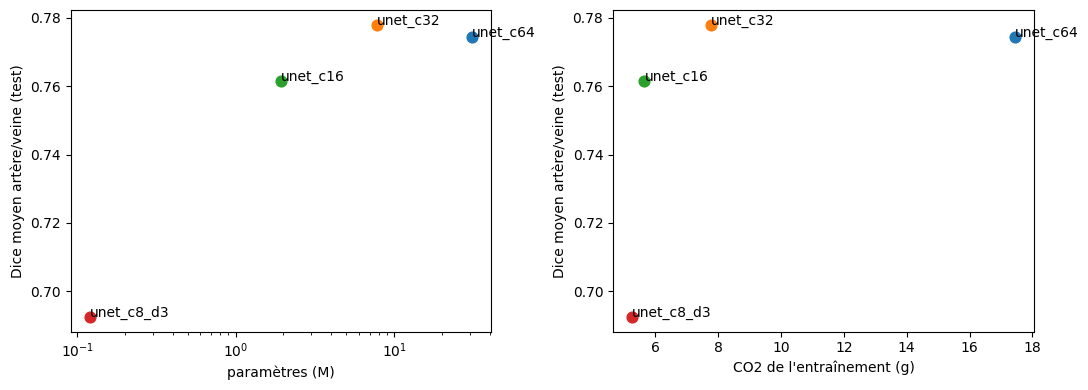


RÉSUMÉ ÉTAPE 4 – tableau Dice / paramètres / CO2 (jeu de test, 31 images)
    modèle  paramètres (M)  Dice artère  Dice veine  Dice vaisseau artère par image veine par image  CO2 (g)  énergie (kWh)  entraînement (min)  inférence (ms/image)  meilleure époque
  unet_c64           31.04        0.764       0.785          0.856    0.760 ± 0.125   0.788 ± 0.121    17.44         0.0606                37.8                   147                60
  unet_c32            7.76        0.769       0.787          0.857    0.764 ± 0.126   0.791 ± 0.122     7.77         0.0270                16.9                    55                54
  unet_c16            1.94        0.751       0.772          0.853    0.744 ± 0.129   0.774 ± 0.122     5.65         0.0196                12.9                    31                56
unet_c8_d3            0.12        0.678       0.707          0.845    0.668 ± 0.128   0.706 ± 0.124     5.26         0.0183                12.9                    20                56


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
# =====================================================================
# Retina A/V – ÉTAPE 4 : IA frugale – U-Net plus légers, même protocole, mesure carbone
# Entraîne plusieurs tailles de U-Net (mêmes données, même séparation, même perte,
# mêmes 60 époques, même graine) puis construit le tableau Dice / paramètres / CO2.
# Prérequis : étapes 1 et 2 faites dans la même session + GPU activé (le modèle unet_c64
# de l'étape 3 y figure déjà si results_unet_c64.json existe). Durée : 20 à 30 min par modèle.
# Chaque modèle terminé est enregistré : si la session s'arrête, relancez la cellule,
# les modèles déjà terminés sont sautés.
# =====================================================================
import os, sys, json, time, subprocess, importlib
import numpy as np

PROJECT_DIR = os.environ.get('RETINA_DIR', '/content/retina_av')
# (nom, canaux de la 1re couche, profondeur). unet_c64 = référence de l'étape 3.
CONFIGS = [('unet_c32', 32, 4), ('unet_c16', 16, 4), ('unet_c8_d3', 8, 3)]
EPOCHS, LR, VAL_EVERY, SEED = 60, 1e-3, 2, 42

def dice_from_conf(conf):
    d = {}
    for c, name in ((0, 'background'), (1, 'artery'), (2, 'vein')):
        tp = conf[c, c]; fp = conf[:, c].sum() - tp; fn = conf[c, :].sum() - tp
        d[name] = float(2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) > 0 else float('nan')
    tp = conf[1:, 1:].sum(); fp = conf[0, 1:].sum(); fn = conf[1:, 0].sum()
    d['vessel'] = float(2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) > 0 else float('nan')
    d['mean_av'] = (d['artery'] + d['vein']) / 2
    return d
def conf_matrix(y_true, y_pred):
    v = y_true != 255
    return np.bincount(y_true[v].astype(np.int64) * 3 + y_pred[v].astype(np.int64), minlength=9).reshape(3, 3)

try:
    import codecarbon
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'codecarbon'], check=False)
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
assert torch.cuda.is_available(), "GPU non activé (Exécution > Modifier le type d'exécution > GPU T4)."
device = 'cuda'
print('GPU :', torch.cuda.get_device_name(0))

CACHE = os.path.join(PROJECT_DIR, 'cache')
sys.path.insert(0, PROJECT_DIR)
import pipeline; importlib.reload(pipeline)
def _normalize(img01):
    fov = img01.max(axis=2) > 0.04
    px = img01[fov] if fov.sum() > 100 else img01.reshape(-1, 3)
    mean, std = px.mean(0), np.maximum(px.std(0), 0.02)
    return np.ascontiguousarray(((img01 - mean) / std).transpose(2, 0, 1), dtype=np.float32)
pipeline.normalize = _normalize          # même normalisation que l'étape 3 (v2)
cfg = json.load(open(os.path.join(PROJECT_DIR, 'pipeline_config.json')))
sp = json.load(open(os.path.join(PROJECT_DIR, 'split.json'))); split = sp['split']
images = np.load(os.path.join(CACHE, 'images.npy'), mmap_mode='r')
labels = np.load(os.path.join(CACHE, 'labels.npy'), mmap_mode='r')
PATCH, BATCH, CLASS_W = cfg['patch'], cfg['batch'], cfg['class_weights']
test_ds = pipeline.RetinaFull(images, labels, split['test'])
val_ds = pipeline.RetinaFull(images, labels, split['val'])
ce_w = torch.tensor(CLASS_W, dtype=torch.float32, device=device)

class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)
class UNet(nn.Module):
    def __init__(self, in_ch=3, n_classes=3, base=64, depth=4):
        super().__init__()
        chs = [base * 2 ** i for i in range(depth + 1)]
        self.inc = DoubleConv(in_ch, chs[0])
        self.downs = nn.ModuleList([DoubleConv(chs[i], chs[i + 1]) for i in range(depth)])
        self.ups = nn.ModuleList([nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in reversed(range(depth))])
        self.dec = nn.ModuleList([DoubleConv(chs[i] * 2, chs[i]) for i in reversed(range(depth))])
        self.out = nn.Conv2d(chs[0], n_classes, 1)
    def forward(self, x):
        skips = [self.inc(x)]
        for d in self.downs: skips.append(d(F.max_pool2d(skips[-1], 2)))
        x = skips.pop()
        for up, dec in zip(self.ups, self.dec):
            x = up(x); x = dec(torch.cat([skips.pop(), x], 1))
        return self.out(x)

def dice_ce_loss(logits, y):
    ce = F.cross_entropy(logits.float(), y, weight=ce_w, ignore_index=255)
    valid = (y != 255); yy = y.clone(); yy[~valid] = 0
    prob = torch.softmax(logits.float(), 1)
    onehot = F.one_hot(yy, 3).permute(0, 3, 1, 2).float(); m = valid.unsqueeze(1).float()
    prob, onehot = prob * m, onehot * m
    inter = (prob * onehot).sum((0, 2, 3)); den = prob.sum((0, 2, 3)) + onehot.sum((0, 2, 3))
    dice = (2 * inter + 1.0) / (den + 1.0)
    return ce + (1.0 - dice[1:].mean())

@torch.no_grad()
def evaluate(model, loader, keep_preds=False):
    model.eval(); conf = np.zeros((3, 3), np.int64); confs, preds = [], []
    for x, y in loader:
        with torch.autocast('cuda', dtype=torch.float16):
            out = model(x.to(device, non_blocking=True))
        p = out.argmax(1).cpu().numpy().astype(np.uint8); yn = y.numpy()
        for pi, yi in zip(p, yn):
            c = conf_matrix(yi, pi); conf += c; confs.append(c)
            if keep_preds: preds.append(pi)
    return conf, confs, preds

def run(name, base, depth):
    torch.manual_seed(SEED); np.random.seed(SEED)
    train_ds = pipeline.RetinaPatches(images, labels, split['train'], PATCH, 1152, 0.7)
    train_loader = DataLoader(train_ds, batch_size=BATCH, num_workers=2, pin_memory=True, persistent_workers=True)
    val_loader = DataLoader(val_ds, batch_size=1, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=1, num_workers=0)
    model = UNet(3, 3, base, depth).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f'\n=== {name} : base={base}, profondeur={depth}, {n_params / 1e6:.2f} M paramètres ===')
    ckpt = os.path.join(PROJECT_DIR, 'models', name + '.pt'); os.makedirs(os.path.dirname(ckpt), exist_ok=True)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(train_loader), eta_min=1e-5)
    scaler = torch.amp.GradScaler('cuda')
    tracker = None
    try:
        from codecarbon import EmissionsTracker
        tracker = EmissionsTracker(project_name=name, measure_power_secs=10, save_to_file=False, log_level='error'); tracker.start()
    except Exception as e:
        print('CodeCarbon indisponible :', e)
    def snap(): return {k: v.detach().clone() for k, v in model.state_dict().items() if 'running_' in k or 'num_batches' in k}
    def bn_ok(): return all(torch.isfinite(v).all().item() for k, v in model.state_dict().items() if 'running_' in k)
    def restore(g): model.load_state_dict({**model.state_dict(), **g})
    good, skipped, history, best, best_ep, t0_all = snap(), 0, [], -1.0, 0, time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); t0 = time.time(); run_l, n_ok = 0.0, 0
        for it, (x, y) in enumerate(train_loader):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16): logits = model(x)
            loss = dice_ce_loss(logits, y)
            if not torch.isfinite(loss): restore(good); skipped += 1; continue
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step(); run_l += loss.item(); n_ok += 1
            if it % 10 == 0:
                if bn_ok(): good = snap()
                else: restore(good); skipped += 1
        rec = {'epoch': ep, 'train_loss': run_l / max(n_ok, 1)}
        if ep % VAL_EVERY == 0 or ep == EPOCHS:
            conf, _, _ = evaluate(model, val_loader); d = dice_from_conf(conf)
            rec.update({'val_artery': d['artery'], 'val_vein': d['vein'], 'val_vessel': d['vessel']})
            if d['mean_av'] > best: best, best_ep = d['mean_av'], ep; torch.save(model.state_dict(), ckpt); rec['saved'] = True
            if ep % 10 == 0 or ep == EPOCHS:
                print(f"ép {ep:3d} | perte {rec['train_loss']:.4f} | val artère {d['artery']:.3f} veine {d['vein']:.3f} | {time.time()-t0:.0f}s/ép")
        history.append(rec)
    train_time = time.time() - t0_all
    em_kg = en = None
    if tracker is not None:
        try:
            em_kg = float(tracker.stop()); dd = getattr(tracker, 'final_emissions_data', None); en = float(dd.energy_consumed) if dd is not None else None
        except Exception as e: print('CodeCarbon :', e)
    model.load_state_dict(torch.load(ckpt, map_location=device))
    conf_t, confs_t, preds_t = evaluate(model, test_loader, keep_preds=True)
    dt_ = dice_from_conf(conf_t); per = [dice_from_conf(c) for c in confs_t]
    ms = lambda k: (float(np.nanmean([p[k] for p in per])), float(np.nanstd([p[k] for p in per])))
    model.eval(); xb = torch.from_numpy(test_ds.get(0)[0])[None].to(device)
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for _ in range(3): model(xb)
        torch.cuda.synchronize(); t0 = time.time()
        for _ in range(10): model(xb)
        torch.cuda.synchronize()
    ms_img = (time.time() - t0) / 10 * 1000
    np.save(os.path.join(PROJECT_DIR, f'pred_test_{name}.npy'), np.stack(preds_t))
    res = {'model': name, 'base_channels': base, 'depth': depth, 'params_M': n_params / 1e6, 'epochs': EPOCHS,
           'train_time_min': train_time / 60, 'inference_ms_per_1024_image': ms_img,
           'emissions_gCO2eq': None if em_kg is None else em_kg * 1000, 'energy_kWh': en,
           'test': dt_, 'test_per_image_mean_std': {k: ms(k) for k in ('artery', 'vein', 'vessel')},
           'best_val_mean_av': best, 'best_epoch': best_ep, 'skipped_batches': skipped}
    json.dump(res, open(os.path.join(PROJECT_DIR, f'results_{name}.json'), 'w'), indent=1)
    print(f"{name} : TEST artère {dt_['artery']:.3f} veine {dt_['vein']:.3f} vaisseau {dt_['vessel']:.3f} | "
          f"{res['emissions_gCO2eq']:.2f} gCO2eq | {train_time/60:.1f} min | meilleure époque {best_ep}")
    del model, opt, train_loader; torch.cuda.empty_cache()

for name, base, depth in CONFIGS:
    if os.path.exists(os.path.join(PROJECT_DIR, f'results_{name}.json')):
        print(name, ': déjà terminé, saut'); continue
    run(name, base, depth)

# ------------------------- tableau final -----------------------------
import pandas as pd, matplotlib.pyplot as plt, glob
rows = []
for f in sorted(glob.glob(os.path.join(PROJECT_DIR, 'results_unet_*.json'))):
    r = json.load(open(f)); t = r['test']; pm = r['test_per_image_mean_std']
    rows.append({'modèle': r['model'], 'paramètres (M)': round(r['params_M'], 2),
                 'Dice artère': round(t['artery'], 3), 'Dice veine': round(t['vein'], 3), 'Dice vaisseau': round(t['vessel'], 3),
                 'artère par image': f"{pm['artery'][0]:.3f} ± {pm['artery'][1]:.3f}", 'veine par image': f"{pm['vein'][0]:.3f} ± {pm['vein'][1]:.3f}",
                 'CO2 (g)': None if r['emissions_gCO2eq'] is None else round(r['emissions_gCO2eq'], 2),
                 'énergie (kWh)': None if not r.get('energy_kWh') else round(r['energy_kWh'], 4),
                 'entraînement (min)': round(r['train_time_min'], 1), 'inférence (ms/image)': round(r['inference_ms_per_1024_image']),
                 'meilleure époque': r.get('best_epoch')})
tab = pd.DataFrame(rows).sort_values('paramètres (M)', ascending=False)
tab.to_csv(os.path.join(PROJECT_DIR, 'table_dice_params_co2.csv'), index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for _, r in tab.iterrows():
    ax[0].scatter(r['paramètres (M)'], (r['Dice artère'] + r['Dice veine']) / 2, s=60); ax[0].annotate(r['modèle'], (r['paramètres (M)'], (r['Dice artère'] + r['Dice veine']) / 2))
    if r['CO2 (g)'] is not None: ax[1].scatter(r['CO2 (g)'], (r['Dice artère'] + r['Dice veine']) / 2, s=60); ax[1].annotate(r['modèle'], (r['CO2 (g)'], (r['Dice artère'] + r['Dice veine']) / 2))
ax[0].set_xscale('log'); ax[0].set_xlabel('paramètres (M)'); ax[0].set_ylabel('Dice moyen artère/veine (test)')
ax[1].set_xlabel('CO2 de l\'entraînement (g)'); ax[1].set_ylabel('Dice moyen artère/veine (test)')
plt.tight_layout(); fig.savefig(os.path.join(PROJECT_DIR, 'fig_frugal.png'), dpi=110); plt.show()
summary = '\n'.join(['=' * 60, 'RÉSUMÉ ÉTAPE 4 – tableau Dice / paramètres / CO2 (jeu de test, 31 images)', '=' * 60, tab.to_string(index=False)])
print('\n' + summary); open(os.path.join(PROJECT_DIR, 'summary_step4.txt'), 'w').write(summary)
try:
    from google.colab import files
    for f in ('summary_step4.txt', 'table_dice_params_co2.csv', 'fig_frugal.png'): files.download(os.path.join(PROJECT_DIR, f))
except Exception: pass


## Étape 5 – Biomarqueurs vasculaires simplifiés
**Ce que fait la cellule** : à partir des masques prédits et des masques de référence du jeu de test, calcule la densité vasculaire, la dimension fractale (comptage de boîtes), le calibre moyen des artères et des veines (carte de distance sur le squelette) et un rapport artères/veines simplifié ; compare prédiction et référence (corrélation de Pearson, erreur absolue, biais).

**Limite à écrire dans le README** : ce ne sont **pas** les CRAE, CRVE et AVR standard (pas de disque optique, pas de formule de Knudtson) ; le calibre est en pixels.

auto-test calibre (attendu ~6) : 5.99 | dim. fractale d'un trait épais (entre 1 et 2, normal) : 1.22


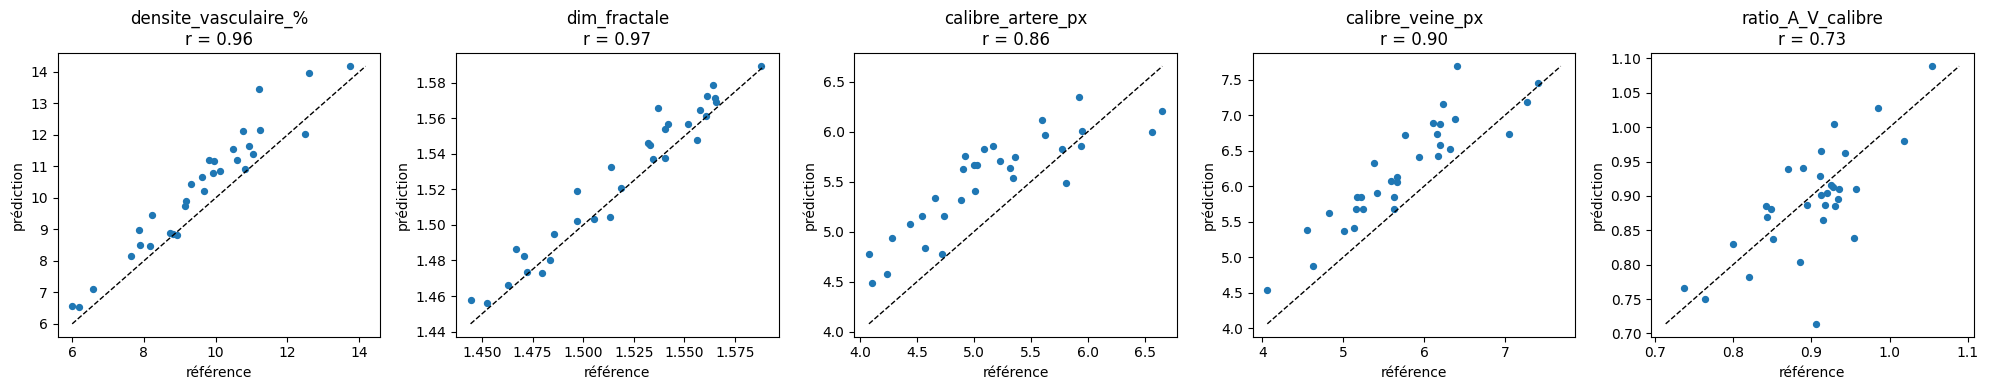

RÉSUMÉ ÉTAPE 5 – biomarqueurs (unet_c64, 31 images de test)
                       n  moy_ref  moy_pred  r_pearson  erreur_abs_moy  biais_pred_moins_ref  erreur_relative_%
biomarqueur                                                                                                    
densite_vasculaire_%  31    9.604    10.322      0.962           0.754                 0.718              7.856
dim_fractale          31    1.519     1.526      0.974           0.009                 0.007              0.594
calibre_artere_px     31    5.143     5.506      0.856           0.454                 0.362              8.829
calibre_veine_px      31    5.728     6.213      0.903           0.510                 0.485              8.909
ratio_A_V_calibre     31    0.901     0.893      0.728           0.042                -0.009              4.701
Rappel : versions simplifiées ; calibre en pixels (image 1024x1024) ; pas de CRAE/CRVE/AVR standard.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
# =====================================================================
# Retina A/V – ÉTAPE 5 : biomarqueurs vasculaires (version simplifiée)
# Calculés à partir des masques PRÉDITS et des masques de RÉFÉRENCE (jeu de test),
# puis comparés : corrélation, erreur absolue, biais.
# Prérequis : étape 3 exécutée dans la même session (pred_test_unet_c64.npy présent).
# Biomarqueurs : densité vasculaire, dimension fractale (box-counting),
# calibre moyen artères / veines (carte de distance sur le squelette), rapport A/V simplifié.
# ATTENTION : ce ne sont PAS les CRAE/CRVE/AVR standard (pas de disque optique, pas de formule de Knudtson).
# =====================================================================
import os, json, numpy as np, pandas as pd
from scipy import ndimage as ndi
from skimage.morphology import skeletonize
import matplotlib.pyplot as plt

PROJECT_DIR = os.environ.get('RETINA_DIR', '/content/retina_av')
MODEL_NAME  = os.environ.get('RETINA_MODEL', 'unet_c64')
PX_UM = None   # taille du pixel en micromètres si connue (sinon calibres en pixels)

CACHE = os.path.join(PROJECT_DIR, 'cache')
sp = json.load(open(os.path.join(PROJECT_DIR, 'split.json')))
test_idx = sp['split']['test']
images = np.load(os.path.join(CACHE, 'images.npy'), mmap_mode='r')
labels = np.load(os.path.join(CACHE, 'labels.npy'), mmap_mode='r')
preds = np.load(os.path.join(PROJECT_DIR, f'pred_test_{MODEL_NAME}.npy'))
assert len(preds) == len(test_idx), 'nombre de prédictions différent du nombre d\'images de test'

def fractal_dimension(mask):
    """Box-counting sur un masque binaire. Retourne la pente de log N(s) en fonction de log(1/s)."""
    if mask.sum() < 50: return np.nan
    H, W = mask.shape; n = 2 ** int(np.floor(np.log2(min(H, W))))
    m = mask[:n, :n]
    sizes = [2 ** k for k in range(1, int(np.log2(n)))]      # 2 .. n/2
    counts = []
    for s in sizes:
        b = m.reshape(n // s, s, n // s, s).any(axis=(1, 3))
        counts.append(b.sum())
    sizes, counts = np.array(sizes, float), np.array(counts, float)
    keep = counts > 0
    slope = np.polyfit(np.log(1.0 / sizes[keep]), np.log(counts[keep]), 1)[0]
    return float(slope)

def mean_caliber(mask):
    """Calibre moyen (pixels) : 2 x distance au fond, échantillonné sur le squelette."""
    if mask.sum() < 50: return np.nan
    dist = ndi.distance_transform_edt(mask)
    skel = skeletonize(mask)
    if skel.sum() == 0: return np.nan
    return float(2.0 * dist[skel].mean())

def biomarkers(cls, fov):
    """cls : carte de classes (0 fond, 1 artère, 2 veine, 255 ignoré/croisement). fov : champ de vue booléen."""
    vessel = (cls != 0) & fov
    art, vei = (cls == 1), (cls == 2)
    ca, cv = mean_caliber(art), mean_caliber(vei)
    return {'densite_vasculaire_%': 100.0 * vessel.sum() / max(fov.sum(), 1),
            'dim_fractale': fractal_dimension(vessel),
            'calibre_artere_px': ca, 'calibre_veine_px': cv,
            'ratio_A_V_calibre': ca / cv if cv and not np.isnan(cv) else np.nan}

# auto-test sur un masque synthétique : un trait de 6 px de large
_t = np.zeros((256, 256), bool); _t[100:106, 20:230] = True
print('auto-test calibre (attendu ~6) :', round(mean_caliber(_t), 2), '| dim. fractale d\'un trait épais (entre 1 et 2, normal) :', round(fractal_dimension(_t), 2))

rows = []
for j, i in enumerate(test_idx):
    fov = np.asarray(images[i]).max(axis=2) > 10
    gt, pr = np.asarray(labels[i]), preds[j].astype(np.int64)
    pr = np.where(gt == 255, 255, pr)          # on neutralise les pixels ignorés de la référence
    bg, bp = biomarkers(gt, fov), biomarkers(pr, fov)
    row = {'image': sp['names'][i]}
    for k in bg: row[k + '_ref'], row[k + '_pred'] = bg[k], bp[k]
    rows.append(row)
df = pd.DataFrame(rows).set_index('image')
df.round(4).to_csv(os.path.join(PROJECT_DIR, f'biomarkers_{MODEL_NAME}.csv'))

names = ['densite_vasculaire_%', 'dim_fractale', 'calibre_artere_px', 'calibre_veine_px', 'ratio_A_V_calibre']
res = []
for k in names:
    a, b = df[k + '_ref'].values, df[k + '_pred'].values
    ok = ~(np.isnan(a) | np.isnan(b))
    a, b = a[ok], b[ok]
    r = float(np.corrcoef(a, b)[0, 1]) if len(a) > 2 else np.nan
    res.append({'biomarqueur': k, 'n': int(len(a)), 'moy_ref': a.mean(), 'moy_pred': b.mean(),
                'r_pearson': r, 'erreur_abs_moy': float(np.abs(a - b).mean()),
                'biais_pred_moins_ref': float((b - a).mean()),
                'erreur_relative_%': float(100 * np.abs(a - b).mean() / np.abs(a).mean())})
tab = pd.DataFrame(res).set_index('biomarqueur')
tab.round(3).to_csv(os.path.join(PROJECT_DIR, f'biomarkers_summary_{MODEL_NAME}.csv'))

fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a_, k in zip(ax, names):
    x, y = df[k + '_ref'], df[k + '_pred']
    a_.scatter(x, y, s=18); lo, hi = np.nanmin([x.min(), y.min()]), np.nanmax([x.max(), y.max()])
    a_.plot([lo, hi], [lo, hi], 'k--', lw=1); a_.set_title(f"{k}\nr = {tab.loc[k, 'r_pearson']:.2f}")
    a_.set_xlabel('référence'); a_.set_ylabel('prédiction')
plt.tight_layout(); fig.savefig(os.path.join(PROJECT_DIR, f'fig_biomarkers_{MODEL_NAME}.png'), dpi=110); plt.show()

summary = ['=' * 60, f'RÉSUMÉ ÉTAPE 5 – biomarqueurs ({MODEL_NAME}, {len(df)} images de test)', '=' * 60,
           tab.round(3).to_string(),
           'Rappel : versions simplifiées ; calibre en pixels (image 1024x1024) ; pas de CRAE/CRVE/AVR standard.']
print('\n'.join(summary))
open(os.path.join(PROJECT_DIR, f'summary_step5_{MODEL_NAME}.txt'), 'w').write('\n'.join(summary))
try:
    from google.colab import files
    for f in (f'summary_step5_{MODEL_NAME}.txt', f'biomarkers_{MODEL_NAME}.csv', f'biomarkers_summary_{MODEL_NAME}.csv', f'fig_biomarkers_{MODEL_NAME}.png'):
        files.download(os.path.join(PROJECT_DIR, f))
except Exception:
    pass


## Étape 6 – README GitHub (à écrire avec vos chiffres réels)
Plan : contexte et objectif ; données (Rotterdam RAV, licence, citation arXiv:2512.17322) ; méthode (pipeline, modèle, perte, protocole) ; résultats (tableau Dice / paramètres / CO₂, biomarqueurs) ; limites (une graine, 31 images de test, croisements ignorés, photos couleur seulement, pas de FFA, biomarqueurs simplifiés) ; pistes (autres jeux, version multimodale, CRAE/CRVE exacts). Envoyez-moi les blocs « RÉSUMÉ » des étapes 3, 4 et 5 : je rédige le README et adapte votre CV.